In [1]:
import numpy as np
import pandas as pd

In [2]:
df=pd.read_csv('../data/soil_measures.csv')
df.shape

(2200, 5)

In [3]:
df.sample(42)

,N,P,K,ph,crop
1982,108,60,17,6.558903,cotton
1775,44,47,45,6.579441,papaya
571,2,56,23,7.550091,mothbeans
2183,93,26,27,7.288212,coffee
1484,120,16,51,6.547042,muskmelon
225,22,67,78,6.204091,chickpea
236,57,58,77,7.978997,chickpea
1952,123,50,16,6.498052,cotton
2025,76,56,39,6.551130,jute
726,49,68,22,7.127064,blackgram


##Exploratory Data Analysis

In [4]:
df.isnull().sum()

,0
N,0
P,0
K,0
ph,0
crop,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   N       2200 non-null   int64  
 1   P       2200 non-null   int64  
 2   K       2200 non-null   int64  
 3   ph      2200 non-null   float64
 4   crop    2200 non-null   object 
dtypes: float64(1), int64(3), object(1)
memory usage: 86.1+ KB


In [6]:
df.describe()

,N,P,K,ph
count,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,6.469480
std,36.917334,32.985883,50.647931,0.773938
min,0.000000,5.000000,5.000000,3.504752
25%,21.000000,28.000000,20.000000,5.971693
50%,37.000000,51.000000,32.000000,6.425045
75%,84.250000,68.000000,49.000000,6.923643
max,140.000000,145.000000,205.000000,9.935091


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

array([[<Axes: title={'center': 'N'}>, <Axes: title={'center': 'P'}>],
       [<Axes: title={'center': 'K'}>, <Axes: title={'center': 'ph'}>]],
      dtype=object)

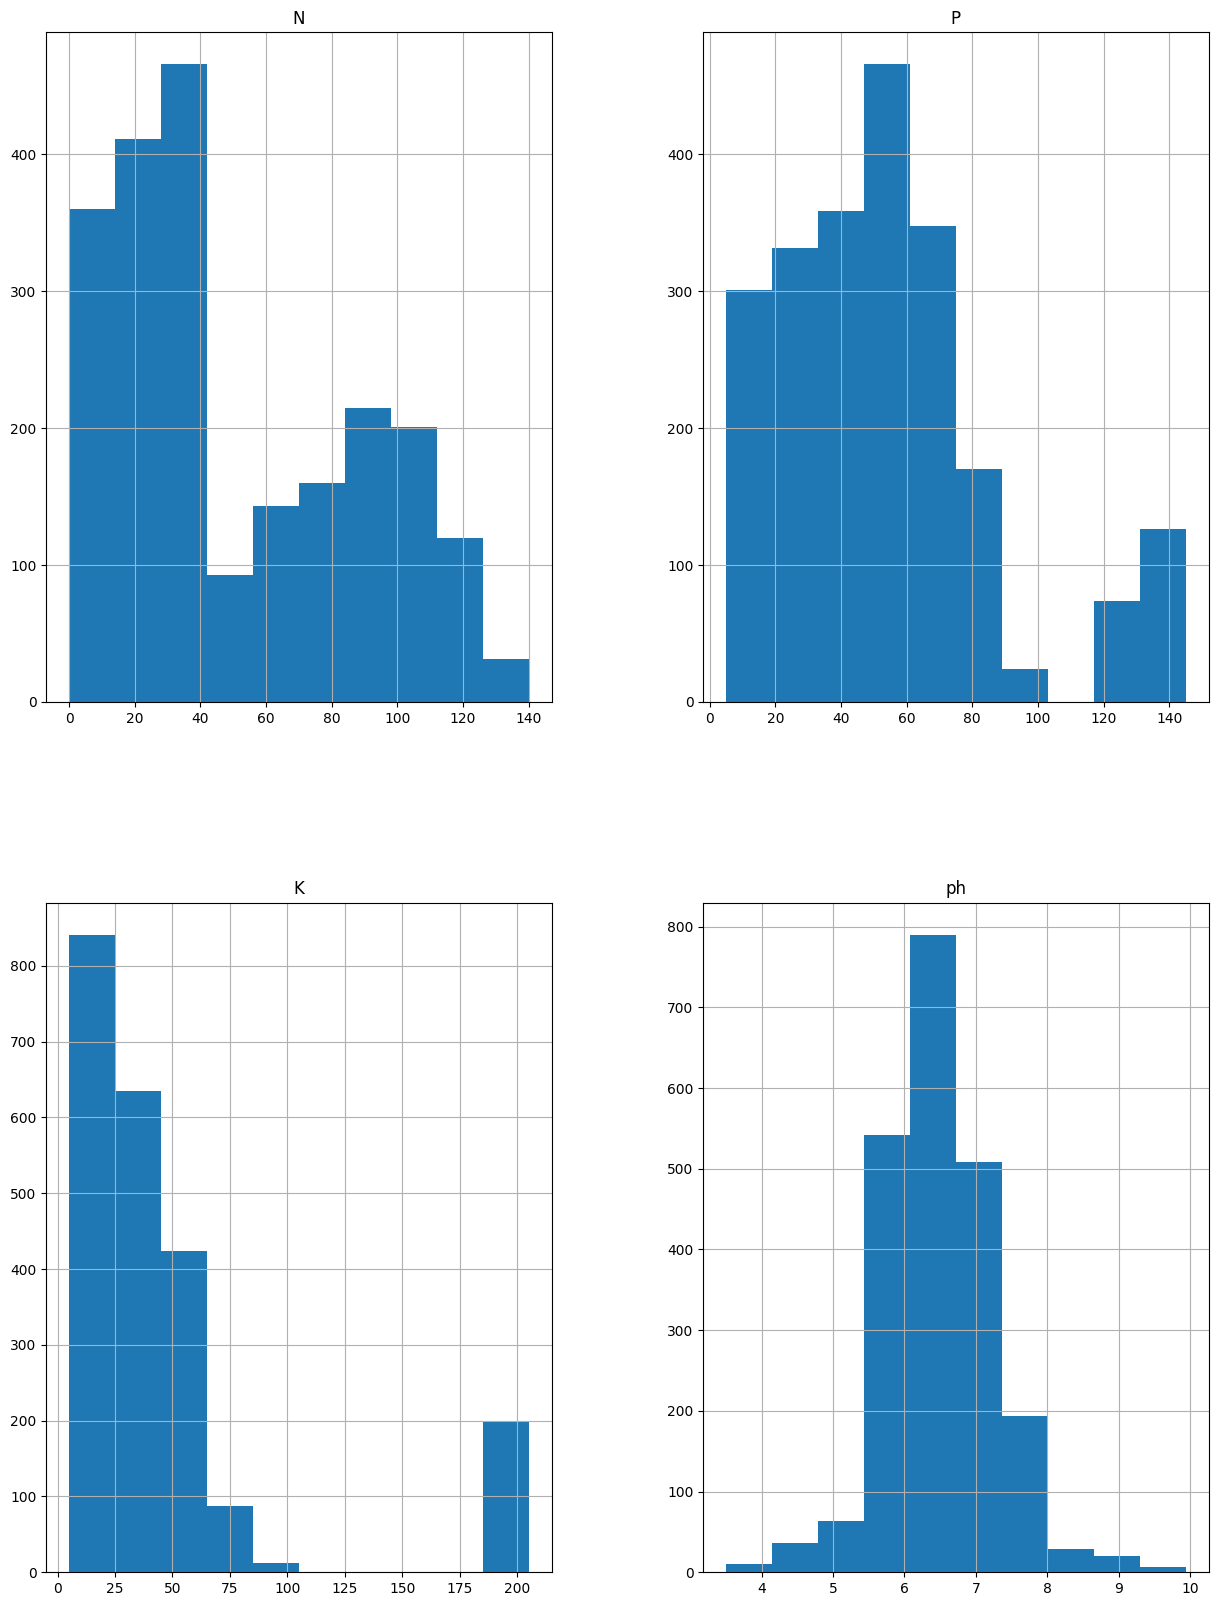

In [8]:
df.hist(bins=10, figsize=(15,20))

<Axes: xlabel='N', ylabel='Density'>

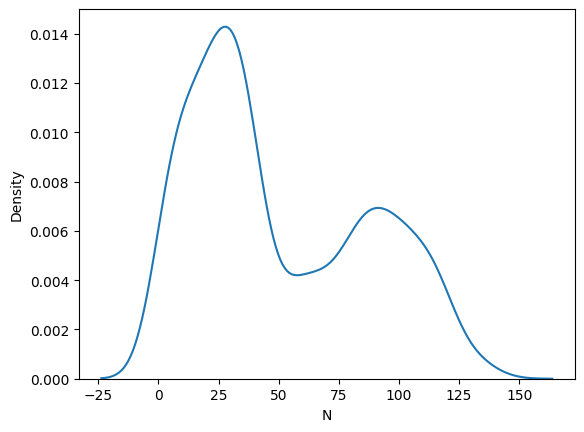

In [9]:
sns.kdeplot(df['N'])

<Axes: xlabel='P', ylabel='Density'>

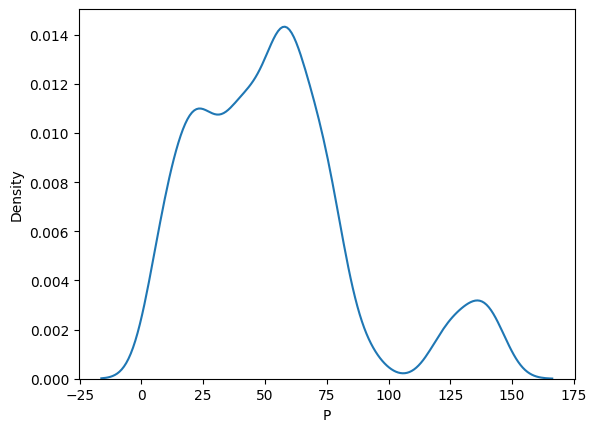

In [10]:
sns.kdeplot(df['P'])

<Axes: xlabel='K', ylabel='Density'>

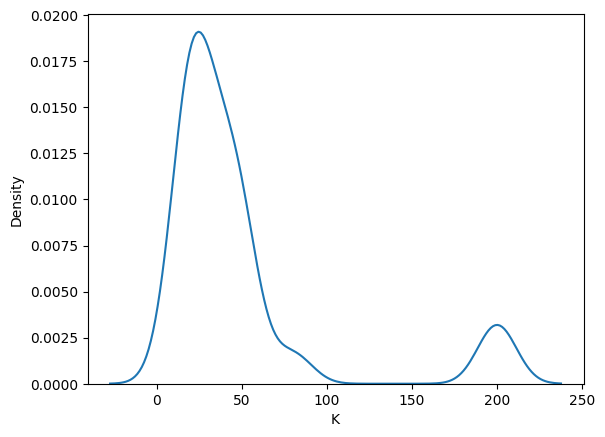

In [11]:
sns.kdeplot(df['K'])

<Axes: xlabel='ph', ylabel='Density'>

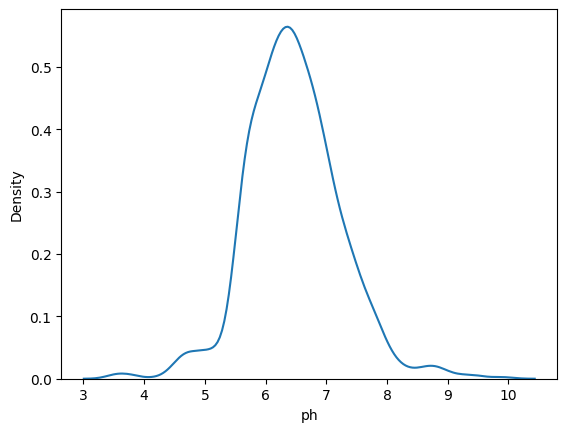

In [12]:
sns.kdeplot(df['ph'])

##Feature Engineering


In [13]:
df['N_P_ratio'] = df['N'] / (df['P'] + 1e-5)
df['K_P_ratio'] = df['K'] / (df['P'] + 1e-5)
df['N_K_ratio'] = df['N'] / (df['K'] + 1e-5)

In [14]:
df['high_potassium_flag'] = (df['K'] > 150).astype(int)
df['high_phosphorus_flag'] = (df['P'] > 100).astype(int)

##Model Preparation
Splitting dataset into train,test and validation for model preparation


In [15]:
from sklearn.model_selection import train_test_split

x = df.drop(columns=['crop'])
y = df['crop']

x_train_split, x_test, y_train_split, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

x_train, x_validate, y_train, y_validate = train_test_split(
    x_train_split,
    y_train_split,
    test_size=0.125,   # 10% of the complete dataset
    random_state=42,
    stratify=y_train_split
)

print('Training data:', x_train.shape)
print('Validation data:', x_validate.shape)
print('Test data:', x_test.shape)

Training data: (1540, 9)
Validation data: (220, 9)
Test data: (440, 9)


In [16]:
x_train.head(), y_train.head()

(       N    P    K        ph  N_P_ratio  K_P_ratio  N_K_ratio  \
 921   40   27   45  5.885638   1.481481   1.666666   0.888889   
 437   17   64   16  7.161798   0.265625   0.250000   1.062499   
 319   23   65   20  5.833940   0.353846   0.307692   1.149999   
 1863   1   12   30  5.562224   0.083333   2.499998   0.033333   
 1219   4  136  204  5.898944   0.029412   1.500000   0.019608   
 
       high_potassium_flag  high_phosphorus_flag  
 921                     0                     0  
 437                     0                     0  
 319                     0                     0  
 1863                    0                     0  
 1219                    1                     1  ,
 921     pomegranate
 437      pigeonpeas
 319     kidneybeans
 1863        coconut
 1219         grapes
 Name: crop, dtype: object)

## Try Different Algorithms



In [17]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

# Algorithms and their hyperparameters
models = {
    'Logistic Regression': (
        Pipeline([
            ('scaler', StandardScaler()),
            ('model', LogisticRegression(max_iter=2000, random_state=42))
        ]),
        {
            'model__C': [0.1, 1, 10],
            'model__solver': ['lbfgs']
        }
    ),

    'KNN': (
        Pipeline([
            ('scaler', StandardScaler()),
            ('model', KNeighborsClassifier())
        ]),
        {
            'model__n_neighbors': [3, 5, 7, 9],
            'model__weights': ['uniform', 'distance']
        }
    ),

    'SVM': (
        Pipeline([
            ('scaler', StandardScaler()),
            ('model', SVC())
        ]),
        {
            'model__C': [0.1, 1, 10],
            'model__kernel': ['rbf', 'linear']
        }
    ),

    'Random Forest': (
        RandomForestClassifier(random_state=42),
        {
            'n_estimators': [100, 200],
            'max_depth': [10, 20, None],
            'min_samples_leaf': [1, 2, 4],
            'max_features': ['sqrt', 'log2']
        }
    ),

    'Extra Trees': (
        ExtraTreesClassifier(random_state=42),
        {
            'n_estimators': [100, 200],
            'max_depth': [10, 20, None],
            'min_samples_leaf': [1, 2, 4],
            'max_features': ['sqrt', 'log2']
        }
    ),

    'Gradient Boosting': (
        GradientBoostingClassifier(random_state=42),
        {
            'n_estimators': [100, 150],
            'learning_rate': [0.05, 0.1],
            'max_depth': [2, 3, 4]
        }
    )
}

## Hyperparameter Tuning + Model Comparison

In [18]:
results = []
best_models = {}

for name, (model, param_grid) in models.items():
    print(f'\nTuning {name}...')

    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        cv=3,
        scoring='accuracy',
        n_jobs=-1
    )

    grid.fit(x_train, y_train)

    best_model = grid.best_estimator_
    best_models[name] = best_model

    train_pred = best_model.predict(x_train)
    val_pred = best_model.predict(x_validate)

    train_accuracy = accuracy_score(y_train, train_pred)
    val_accuracy = accuracy_score(y_validate, val_pred)

    results.append({
        'Algorithm': name,
        'CV Accuracy': grid.best_score_,
        'Train Accuracy': train_accuracy,
        'Validation Accuracy': val_accuracy,
        'Best Parameters': grid.best_params_
    })

    print('Best Parameters:', grid.best_params_)
    print(f'CV Accuracy:         {grid.best_score_:.4f}')
    print(f'Training Accuracy:   {train_accuracy:.4f}')
    print(f'Validation Accuracy: {val_accuracy:.4f}')


Tuning Logistic Regression...
Best Parameters: {'model__C': 10, 'model__solver': 'lbfgs'}
CV Accuracy:         0.6864
Training Accuracy:   0.7169
Validation Accuracy: 0.6636

Tuning KNN...
Best Parameters: {'model__n_neighbors': 7, 'model__weights': 'distance'}
CV Accuracy:         0.7526
Training Accuracy:   1.0000
Validation Accuracy: 0.7227

Tuning SVM...
Best Parameters: {'model__C': 10, 'model__kernel': 'rbf'}
CV Accuracy:         0.7688
Training Accuracy:   0.8071
Validation Accuracy: 0.7500

Tuning Random Forest...
Best Parameters: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'n_estimators': 100}
CV Accuracy:         0.8052
Training Accuracy:   0.9058
Validation Accuracy: 0.7591

Tuning Extra Trees...
Best Parameters: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 100}
CV Accuracy:         0.7818
Training Accuracy:   0.9929
Validation Accuracy: 0.7318

Tuning Gradient Boosting...
Best Parameters: {'learning_rate': 0.05, 'max

In [19]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('Validation Accuracy', ascending=False).reset_index(drop=True)

results_df[['Algorithm', 'CV Accuracy', 'Train Accuracy', 'Validation Accuracy']]

,Algorithm,CV Accuracy,Train Accuracy,Validation Accuracy
0,Gradient Boosting,0.779225,0.965584,0.772727
1,Random Forest,0.805192,0.905844,0.759091
2,SVM,0.768840,0.807143,0.750000
3,Extra Trees,0.781824,0.992857,0.731818
4,KNN,0.752593,1.000000,0.722727
5,Logistic Regression,0.686363,0.716883,0.663636


## Select the Best Model

The model with the highest validation accuracy is selected. The test set is used only once here for the final unbiased evaluation.

In [20]:
best_name = results_df.iloc[0]['Algorithm']
best_model = best_models[best_name]

print('Best Algorithm:', best_name)
print('Best Model:', best_model)

Best Algorithm: Gradient Boosting
Best Model: GradientBoostingClassifier(learning_rate=0.05, max_depth=2, n_estimators=150,
                           random_state=42)


Final Test Accuracy: 0.7773

Classification Report:
              precision    recall  f1-score   support

       apple       0.62      0.50      0.56        20
      banana       1.00      1.00      1.00        20
   blackgram       0.59      0.65      0.62        20
    chickpea       1.00      1.00      1.00        20
     coconut       0.67      0.60      0.63        20
      coffee       0.95      1.00      0.98        20
      cotton       1.00      1.00      1.00        20
      grapes       0.58      0.70      0.64        20
        jute       0.71      0.85      0.77        20
 kidneybeans       0.82      0.90      0.86        20
      lentil       0.45      0.50      0.48        20
       maize       0.95      0.95      0.95        20
       mango       0.80      0.80      0.80        20
   mothbeans       0.89      0.80      0.84        20
    mungbean       0.82      0.90      0.86        20
   muskmelon       0.50      0.50      0.50        20
      orange       1.00      

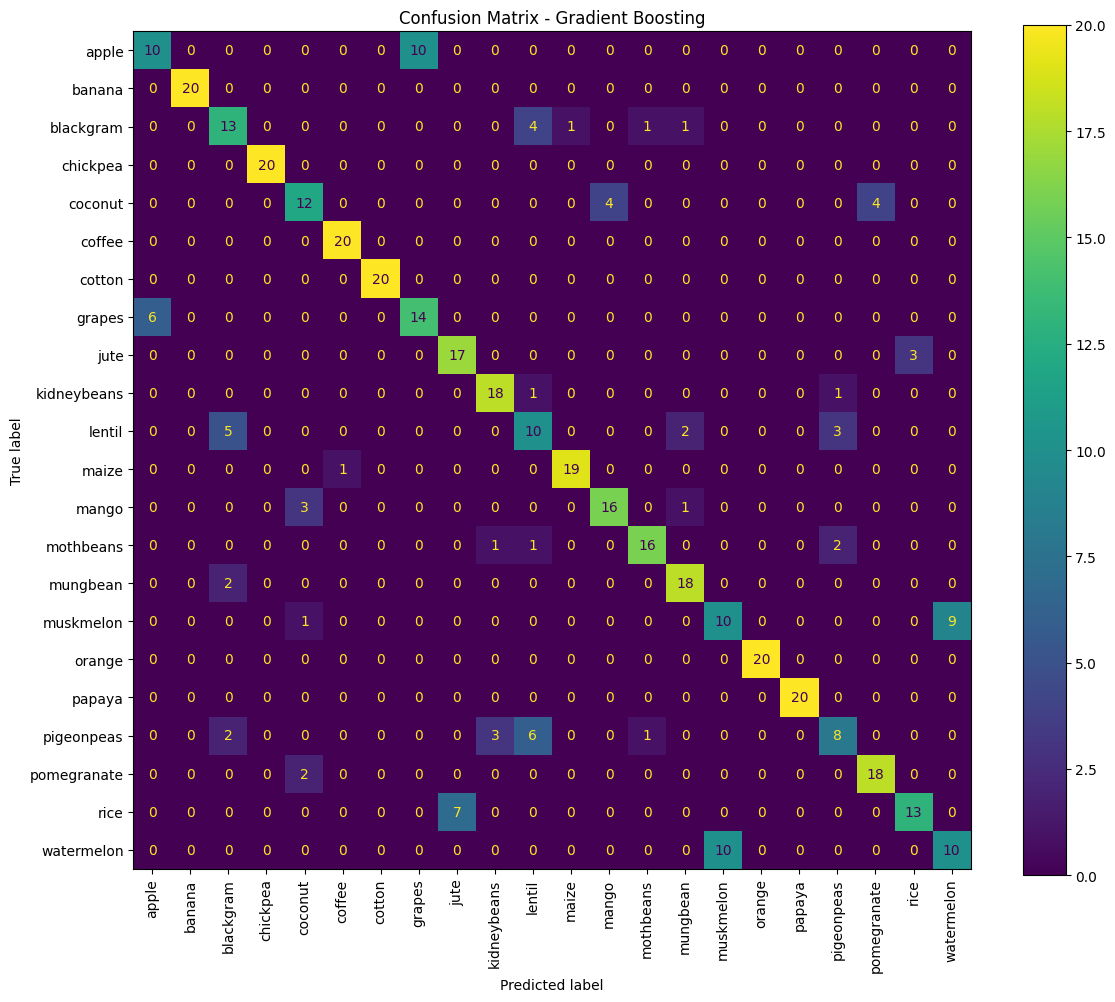

In [22]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_test_pred = best_model.predict(x_test)

test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Final Test Accuracy: {test_accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_test_pred))

cm = confusion_matrix(y_test, y_test_pred, labels=best_model.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_model.classes_
)

fig, ax = plt.subplots(figsize=(12, 10))
disp.plot(ax=ax, xticks_rotation=90)

plt.title(f"Confusion Matrix - {best_name}")
plt.tight_layout()
plt.show()

## Feature Importance

For tree-based models, feature importance helps us understand which soil measurements/features contributed most to the prediction.

                Feature  Importance
2                     K    0.220434
5             K_P_ratio    0.158565
6             N_K_ratio    0.138561
0                     N    0.125933
3                    ph    0.125911
1                     P    0.116204
4             N_P_ratio    0.088819
8  high_phosphorus_flag    0.016669
7   high_potassium_flag    0.008903


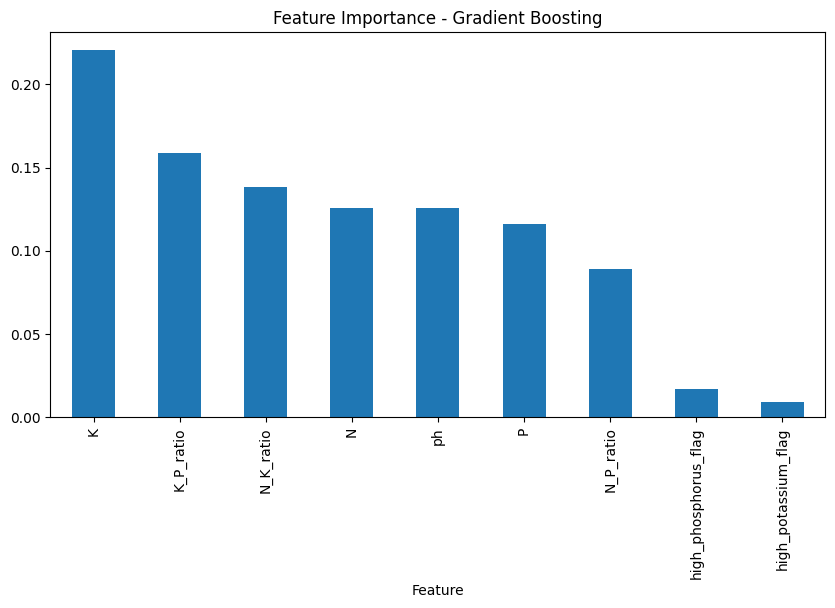

In [23]:
if hasattr(best_model, 'feature_importances_'):
    importance = pd.DataFrame({
        'Feature': x_train.columns,
        'Importance': best_model.feature_importances_
    }).sort_values('Importance', ascending=False)

    print(importance)
    importance.plot(x='Feature', y='Importance', kind='bar', legend=False, figsize=(10, 5))
    plt.title(f'Feature Importance - {best_name}')
    plt.show()
else:
    print('Feature importance is not directly available for this model.')

## Final Prediction Function



In [24]:
def predict_crop(N, P, K, ph):
    new_data = pd.DataFrame({
        'N': [N],
        'P': [P],
        'K': [K],
        'ph': [ph]
    })

    # Apply the same feature engineering used during training.
    new_data['N_P_ratio'] = new_data['N'] / (new_data['P'] + 1e-5)
    new_data['K_P_ratio'] = new_data['K'] / (new_data['P'] + 1e-5)
    new_data['N_K_ratio'] = new_data['N'] / (new_data['K'] + 1e-5)
    new_data['high_potassium_flag'] = (new_data['K'] > 150).astype(int)
    new_data['high_phosphorus_flag'] = (new_data['P'] > 100).astype(int)

    prediction = best_model.predict(new_data)[0]
    print('Recommended Crop:', prediction)
    return prediction

# Example
predict_crop(90, 40, 40, 6.5)

Recommended Crop: jute


'jute'